### Seattle Weather Analysis Dashboard


In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
weather = pd.read_csv("seattle-weather.csv")
weather.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [5]:
weather.shape

(1461, 6)

In [8]:
weather.columns

Index(['date', 'precipitation', 'temp_max', 'temp_min', 'wind', 'weather'], dtype='object')

In [9]:
weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   object 
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   object 
dtypes: float64(4), object(2)
memory usage: 68.6+ KB


> from above we know that there are no null rows/ values in the dataset

In [12]:
weather.isnull()

,date,precipitation,temp_max,temp_min,wind,weather
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,False,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
1456,False,False,False,False,False,False
1457,False,False,False,False,False,False
1458,False,False,False,False,False,False
1459,False,False,False,False,False,False


In [13]:
weather.isnull().sum()

date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64

In [10]:
weather.describe()

,precipitation,temp_max,temp_min,wind
count,1461.000000,1461.000000,1461.000000,1461.000000
mean,3.029432,16.439083,8.234771,3.241136
std,6.680194,7.349758,5.023004,1.437825
min,0.000000,-1.600000,-7.100000,0.400000
25%,0.000000,10.600000,4.400000,2.200000
50%,0.000000,15.600000,8.300000,3.000000
75%,2.800000,22.200000,12.200000,4.000000
max,55.900000,35.600000,18.300000,9.500000


In [14]:
print("Average Maximum Temperature : ", np.mean(weather["temp_max"]))

Average Maximum Temperature :  16.43908281998631


In [15]:
print("Average Minimum Temperature : ", np.mean(weather["temp_min"]))

Average Minimum Temperature :  8.234770704996578


In [16]:
print("Average Wind : ", np.mean(weather["wind"]))

Average Wind :  3.24113620807666


In [17]:
print("Max temp in Seattle : ", np.max(weather["temp_max"]))
print("Min temp in Seattle : ", np.min(weather["temp_min"]))

Max temp in Seattle :  35.6
Min temp in Seattle :  -7.1


In [19]:
weather['date'] = pd.to_datetime(weather['date'])

weather['year'] = weather['date'].dt.year
weather['month'] = weather['date'].dt.month
weather['month_name'] = weather['date'].dt.month_name()

weather.head()

,date,precipitation,temp_max,temp_min,wind,weather,year,month,month_name
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle,2012,1,January
1,2012-01-02,10.9,10.6,2.8,4.5,rain,2012,1,January
2,2012-01-03,0.8,11.7,7.2,2.3,rain,2012,1,January
3,2012-01-04,20.3,12.2,5.6,4.7,rain,2012,1,January
4,2012-01-05,1.3,8.9,2.8,6.1,rain,2012,1,January


In [23]:
weather["avg_temp"] = (weather["temp_max"] + weather["temp_min"]) / 2
weather[["temp_max", "temp_min", "avg_temp"]].head(10)

,temp_max,temp_min,avg_temp
0,12.8,5.0,8.90
1,10.6,2.8,6.70
2,11.7,7.2,9.45
3,12.2,5.6,8.90
4,8.9,2.8,5.85
5,4.4,2.2,3.30
6,7.2,2.8,5.00
7,10.0,2.8,6.40
8,9.4,5.0,7.20
9,6.1,0.6,3.35


`Analysis 01 - Weather Condition Frequency`

In [28]:
weather_count = weather["weather"].value_counts()
weather_count

weather
rain       641
sun        640
fog        101
drizzle     53
snow        26
Name: count, dtype: int64

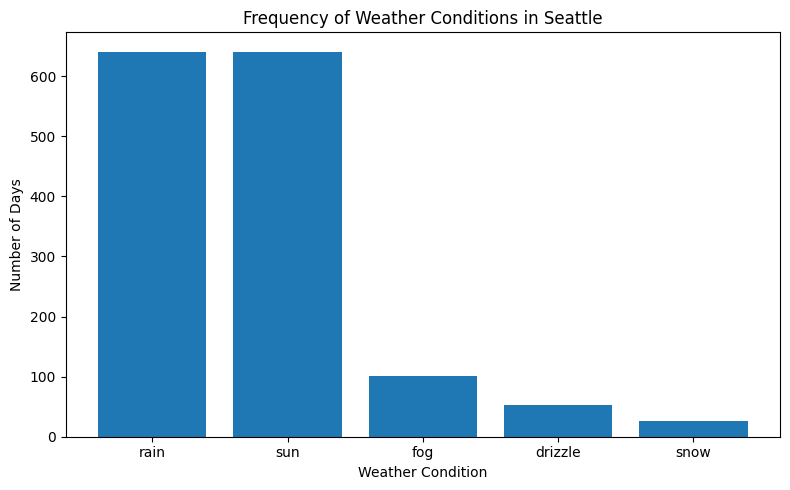

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(weather_count.index, weather_count.values)

plt.title("Frequency of Weather Conditions in Seattle")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Days")

plt.tight_layout()
plt.show()

> [NOTE]

>    During 2012 - 2015:
>        The weather was rainy and sunny moslty, while it snowed rarely/

`Analysis 02 - Monthly Average Temperature`

In [31]:
monthly_temp = weather.groupby('month')["avg_temp"].mean()
monthly_temp

month
1      5.462903
2      6.957522
3      8.622984
4     10.691250
5     14.455242
6     17.322083
7     20.097984
8     20.440726
9     17.141250
10    12.870161
11     7.862500
12     5.759677
Name: avg_temp, dtype: float64

In [40]:
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

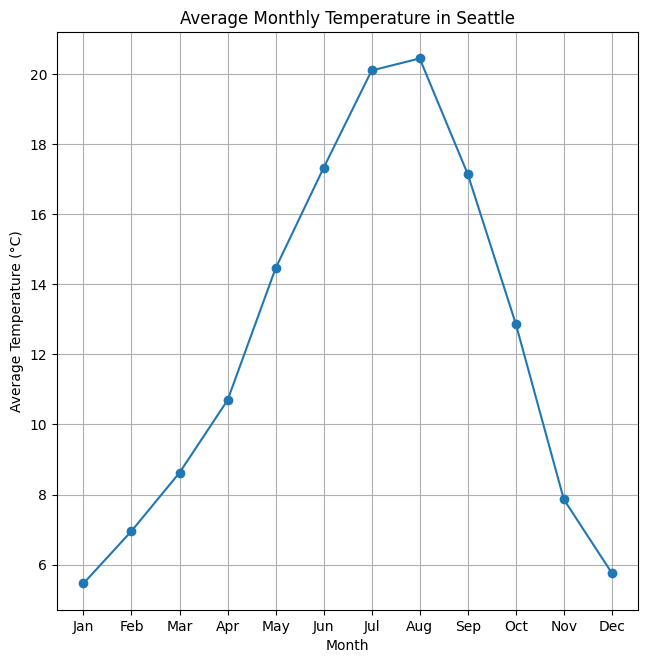

In [45]:
plt.figure(figsize=(7.5, 7.5))

plt.plot(
    month_names,
    monthly_temp.values,
    marker='o'
)

plt.title("Average Monthly Temperature in Seattle")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")

plt.grid()
plt.show()

[NOTE]
Seattle might experience summers during July and August where the temperature crosses 20 degrees celsius.

`Analysis 03 - Wind Analysis`

In [50]:
# Avg wind speed of each month
monthly_wind  = weather.groupby('month')['wind'].mean()
print(monthly_wind)

month
1     3.138710
2     3.786726
3     3.579839
4     3.524167
5     3.120161
6     3.130833
7     2.911290
8     2.750806
9     2.963333
10    2.939516
11    3.482500
12    3.618548
Name: wind, dtype: float64


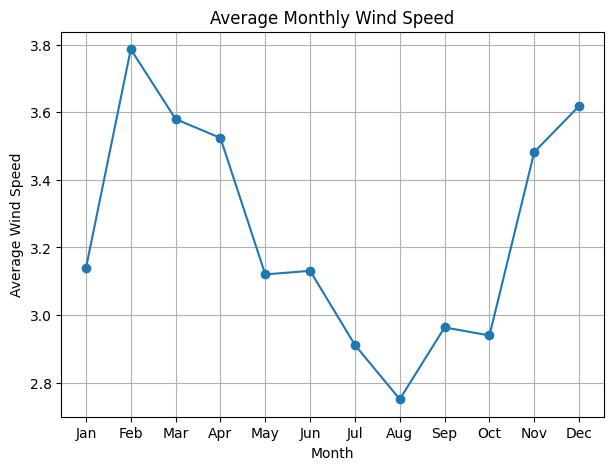

In [52]:
plt.figure(figsize=(7, 5))

plt.plot(
    month_names,
    monthly_wind.values,
    marker='o'
)

plt.title("Average Monthly Wind Speed")
plt.xlabel("Month")
plt.ylabel("Average Wind Speed")

plt.grid()
plt.show()

`Analysis 04 - Extreme Weather`

In [54]:
hot_limit = np.percentile(weather["temp_max"], 90) #90 %ile and above, i.e. top 10%
hot_days =  weather[weather["temp_max"] >= hot_limit]
print("Hot temperature threshold : ", hot_limit)
print("Total Number of Hot Days (top 10%) : ", len(hot_days))

Hot temperature threshold :  26.7
Total Number of Hot Days (top 10%) :  157


In [56]:
rain_limit = np.percentile(weather["precipitation"], 90)
rain_days = weather[weather["precipitation"] > rain_limit]

print("More Rain threshold : ", rain_limit)
print("Total Number of Rainy Days (top 10%) : ", len(rain_days))

More Rain threshold :  9.9
Total Number of Rainy Days (top 10%) :  144
